In [1]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.io.ascii as ascii

from scipy.stats import binned_statistic

from tqdm import tqdm

from scipy.stats import norm

import matplotlib.lines as mlines

from astropy.table import vstack

In [3]:
BBC_P21_highz = ascii.read("../sims/LSST/HIGHZ/FITOPT000_BBC_LSST_HIGHZ.FITRES")
print(BBC_P21_highz.colnames)

['VARNAMES:', 'CID', 'CIDint', 'IDSURVEY', 'TYPE', 'FIELD', 'CUTFLAG_SNANA', 'ERRFLAG_FIT', 'zHEL', 'zHELERR', 'zCMB', 'zCMBERR', 'zHD', 'zHDERR', 'VPEC', 'VPECERR', 'LENSDMU', 'LENSDMUERR', 'MWEBV', 'HOST_LOGMASS', 'HOST_LOGMASS_ERR', 'HOST_LOGSFR', 'HOST_LOGSFR_ERR', 'HOST_LOGsSFR', 'HOST_LOGsSFR_ERR', 'HOST_COLOR', 'HOST_COLOR_ERR', 'HOST_MAG_u', 'HOST_MAG_g', 'HOST_MAG_r', 'HOST_MAG_i', 'HOST_MAG_z', 'HOST_MAG_Y', 'PKMJDINI', 'SNRMAX1', 'SNRMAX2', 'SNRMAX3', 'SNRSUM', 'BANDLIST', 'PKMJD', 'PKMJDERR', 'x1', 'x1ERR', 'c', 'cERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c', 'COV_x1_x0', 'COV_c_x0', 'NDOF', 'FITCHI2', 'FITPROB', 'RADIUS_POP', 'SIM_GENTYPE', 'SIM_TEMPLATE_INDEX', 'SIM_LIBID', 'SIM_NGEN_LIBID', 'SIM_ZCMB', 'SIM_ZFLAG', 'SIM_VPEC', 'SIM_DLMAG', 'SIM_LENSDMU', 'SIM_PEAKMJD', 'SIM_WGT_POP', 'SIM_x1', 'SIM_c', 'SIM_alpha', 'SIM_beta', 'SIM_gammaDM', 'SIM_x0', 'SIM_mB', 'SIM_AV', 'SIM_RV', 'RA', 'DEC', 'TGAPMAX', 'TrestMIN', 'TrestMAX']


In [4]:
BBC_P21_highz_corr_max = ascii.read("../sims/LSST/HIGHZ/FITOPT000_BBC_LSST_HIGHZ_EBV_IGM_MAX.FITRES")
print(BBC_P21_highz_corr_max.colnames)

['VARNAMES:', 'CID', 'CIDint', 'IDSURVEY', 'TYPE', 'FIELD', 'CUTFLAG_SNANA', 'ERRFLAG_FIT', 'zHEL', 'zHELERR', 'zCMB', 'zCMBERR', 'zHD', 'zHDERR', 'VPEC', 'VPECERR', 'LENSDMU', 'LENSDMUERR', 'MWEBV', 'HOST_LOGMASS', 'HOST_LOGMASS_ERR', 'HOST_LOGSFR', 'HOST_LOGSFR_ERR', 'HOST_LOGsSFR', 'HOST_LOGsSFR_ERR', 'HOST_COLOR', 'HOST_COLOR_ERR', 'HOST_MAG_u', 'HOST_MAG_g', 'HOST_MAG_r', 'HOST_MAG_i', 'HOST_MAG_z', 'HOST_MAG_Y', 'PKMJDINI', 'SNRMAX1', 'SNRMAX2', 'SNRMAX3', 'SNRSUM', 'BANDLIST', 'PKMJD', 'PKMJDERR', 'x1', 'x1ERR', 'c', 'cERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c', 'COV_x1_x0', 'COV_c_x0', 'NDOF', 'FITCHI2', 'FITPROB', 'RADIUS_POP', 'SIM_GENTYPE', 'SIM_TEMPLATE_INDEX', 'SIM_LIBID', 'SIM_NGEN_LIBID', 'SIM_ZCMB', 'SIM_ZFLAG', 'SIM_VPEC', 'SIM_DLMAG', 'SIM_LENSDMU', 'SIM_PEAKMJD', 'SIM_WGT_POP', 'SIM_x1', 'SIM_c', 'SIM_alpha', 'SIM_beta', 'SIM_gammaDM', 'SIM_x0', 'SIM_mB', 'SIM_AV', 'SIM_RV', 'RA', 'DEC', 'TGAPMAX', 'TrestMIN', 'TrestMAX']


In [5]:
BBC_P21_highz_corr_med = ascii.read("../sims/LSST/HIGHZ/FITOPT000_BBC_LSST_HIGHZ_EBV_IGM_MED.FITRES")
print(BBC_P21_highz_corr_med.colnames)

['VARNAMES:', 'CID', 'CIDint', 'IDSURVEY', 'TYPE', 'FIELD', 'CUTFLAG_SNANA', 'ERRFLAG_FIT', 'zHEL', 'zHELERR', 'zCMB', 'zCMBERR', 'zHD', 'zHDERR', 'VPEC', 'VPECERR', 'LENSDMU', 'LENSDMUERR', 'MWEBV', 'HOST_LOGMASS', 'HOST_LOGMASS_ERR', 'HOST_LOGSFR', 'HOST_LOGSFR_ERR', 'HOST_LOGsSFR', 'HOST_LOGsSFR_ERR', 'HOST_COLOR', 'HOST_COLOR_ERR', 'HOST_MAG_u', 'HOST_MAG_g', 'HOST_MAG_r', 'HOST_MAG_i', 'HOST_MAG_z', 'HOST_MAG_Y', 'PKMJDINI', 'SNRMAX1', 'SNRMAX2', 'SNRMAX3', 'SNRSUM', 'BANDLIST', 'PKMJD', 'PKMJDERR', 'x1', 'x1ERR', 'c', 'cERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c', 'COV_x1_x0', 'COV_c_x0', 'NDOF', 'FITCHI2', 'FITPROB', 'RADIUS_POP', 'SIM_GENTYPE', 'SIM_TEMPLATE_INDEX', 'SIM_LIBID', 'SIM_NGEN_LIBID', 'SIM_ZCMB', 'SIM_ZFLAG', 'SIM_VPEC', 'SIM_DLMAG', 'SIM_LENSDMU', 'SIM_PEAKMJD', 'SIM_WGT_POP', 'SIM_x1', 'SIM_c', 'SIM_alpha', 'SIM_beta', 'SIM_gammaDM', 'SIM_x0', 'SIM_mB', 'SIM_AV', 'SIM_RV', 'RA', 'DEC', 'TGAPMAX', 'TrestMIN', 'TrestMAX']


In [6]:
BBC_P21_highz_corr_min = ascii.read("../sims/LSST/HIGHZ/FITOPT000_BBC_LSST_HIGHZ_EBV_IGM_MIN.FITRES.gz")
print(BBC_P21_highz_corr_min.colnames)

['VARNAMES:', 'CID', 'CIDint', 'IDSURVEY', 'TYPE', 'FIELD', 'CUTFLAG_SNANA', 'ERRFLAG_FIT', 'zHEL', 'zHELERR', 'zCMB', 'zCMBERR', 'zHD', 'zHDERR', 'VPEC', 'VPECERR', 'LENSDMU', 'LENSDMUERR', 'MWEBV', 'HOST_LOGMASS', 'HOST_LOGMASS_ERR', 'HOST_LOGSFR', 'HOST_LOGSFR_ERR', 'HOST_LOGsSFR', 'HOST_LOGsSFR_ERR', 'HOST_COLOR', 'HOST_COLOR_ERR', 'HOST_MAG_u', 'HOST_MAG_g', 'HOST_MAG_r', 'HOST_MAG_i', 'HOST_MAG_z', 'HOST_MAG_Y', 'PKMJDINI', 'SNRMAX1', 'SNRMAX2', 'SNRMAX3', 'SNRSUM', 'BANDLIST', 'PKMJD', 'PKMJDERR', 'x1', 'x1ERR', 'c', 'cERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c', 'COV_x1_x0', 'COV_c_x0', 'NDOF', 'FITCHI2', 'FITPROB', 'RADIUS_POP', 'SIM_GENTYPE', 'SIM_TEMPLATE_INDEX', 'SIM_LIBID', 'SIM_NGEN_LIBID', 'SIM_ZCMB', 'SIM_ZFLAG', 'SIM_VPEC', 'SIM_DLMAG', 'SIM_LENSDMU', 'SIM_PEAKMJD', 'SIM_WGT_POP', 'SIM_x1', 'SIM_c', 'SIM_alpha', 'SIM_beta', 'SIM_gammaDM', 'SIM_x0', 'SIM_mB', 'SIM_AV', 'SIM_RV', 'RA', 'DEC', 'TGAPMAX', 'TrestMIN', 'TrestMAX']


In [7]:
P21_highz = ascii.read("../sims/LSST/HIGHZ/FITOPT000_LSST_HIGHZ.FITRES")

In [8]:
def create_filt(file):
    
    filt = (np.abs(file['c']) < 0.3) & (np.abs(file['x1']) < 3) & (file['x1ERR'] < 1) & (file['PKMJDERR'] < 2) & (file['FITPROB'] > 0.001) & (file['SIM_AV'] > -9)
    
    return filt

In [9]:
def bin_vals(x,y,num_bins=30):
    bin_edges = np.linspace(np.min(x),np.max(x),num_bins+1)
    
    bin_means, _, _ = binned_statistic(x,y,statistic='median',bins=bin_edges)
    bin_std, _, _ = binned_statistic(x,y,statistic='std',bins=bin_edges)
    bin_count, _, _ = binned_statistic(x,y,statistic='count',bins=bin_edges)
    
    bin_std_errors = bin_std/np.sqrt(bin_count)
    
    return bin_edges, bin_means, bin_std_errors

In [10]:
BBC_P21_lowz = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ.FITRES")

In [11]:
BBC_P21_lowz_corr_max = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ_EBV_IGM_MAX.FITRES")

In [12]:
BBC_P21_lowz_corr_med = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ_EBV_IGM_MED.FITRES")

In [13]:
BBC_P21_lowz_corr_min = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ_EBV_IGM_MIN.FITRES")

In [14]:
P21_lowz = ascii.read("../sims/LSST/LOWZ/FITOPT000_LSST_LOWZ.FITRES")

In [15]:
BBC_P21 = vstack([BBC_P21_lowz,BBC_P21_highz])

In [16]:
BBC_P21_corr_max = vstack([BBC_P21_lowz_corr_max,BBC_P21_highz_corr_max])

In [17]:
BBC_P21_corr_med = vstack([BBC_P21_lowz_corr_med,BBC_P21_highz_corr_med])

In [18]:
BBC_P21_corr_min = vstack([BBC_P21_lowz_corr_min,BBC_P21_highz_corr_min])

In [19]:
P21 = vstack([P21_lowz,P21_highz])

In [20]:
def find_drop(x,y):
    small_drop = True
    i=0
    while (small_drop == True):
        if (y[i]-y[i+1]) > 0.01:
            z_drop = (x[i]+x[i+1])/2
            small_drop = False
        i+=1
        
    return z_drop

In [21]:
def plot_drop(nodust,dust):
    bin_edges = np.arange(np.min(dust['zHD']),np.max(dust['zHD']),0.06)
    bin_zs = (bin_edges[:-1] + bin_edges[1:])/2

    filt = create_filt(nodust)
    corr_filt = create_filt(dust)
    
    bin_count_nodust, _, _ = binned_statistic(nodust['zHD'][filt],nodust['zHD'][filt],statistic='count',bins=bin_edges)
    bin_count_dust, _, _ = binned_statistic(dust['zHD'][corr_filt],dust['zHD'][corr_filt],statistic='count',bins=bin_edges)
    
    bin_edges_nodust, c_bin_means_nodust, c_bin_std_nodust = bin_vals(nodust['zHD'][filt],nodust['c'][filt],num_bins=len(bin_zs))
    bin_edges_dust, c_bin_means_dust, c_bin_std_dust = bin_vals(dust['zHD'][corr_filt],dust['c'][corr_filt],num_bins=len(bin_zs))
    
    z_drop = find_drop(bin_zs,bin_count_dust/bin_count_nodust)
    
    #PLOTTING
    fig = plt.figure(figsize=(5,6))
    ax1 = fig.add_axes([0.08, 0.52, 0.86, 0.43])

    plt.scatter(bin_zs,
                bin_count_dust/bin_count_nodust,label='highz',zorder=2)
    legend1 = plt.legend(loc='lower right')

    plt.axvline(x=z_drop,
                color='C0',ls='--',alpha=0.4)

    ax = plt.gca()
    orange_dotted = mlines.Line2D([], [], color="C0", linestyle="--", label=f"$z={z_drop:.2f}$",alpha=0.6)
    legend2 = ax.legend(handles=[orange_dotted],loc='lower left')

    ax.add_artist(legend1)

    plt.title("LSST Simulation",fontsize=16)
    plt.ylabel("$N_\mathrm{i.g. dust}/N_\mathrm{nominal}$",fontsize=14)

    ax2 = fig.add_axes([0.08, 0.09, 0.86, 0.43])
    plt.scatter(bin_zs,c_bin_means_nodust-c_bin_means_dust,zorder=2)
    plt.xlabel("Binned $z$",fontsize=14)
    plt.ylabel("Binned $c_\mathrm{nominal}-c_\mathrm{i.g. dust}$",fontsize=14)

    plt.axvline(x=z_drop,
                color='C0',ls='--',alpha=0.4)

#     plt.show()
    
    return z_drop

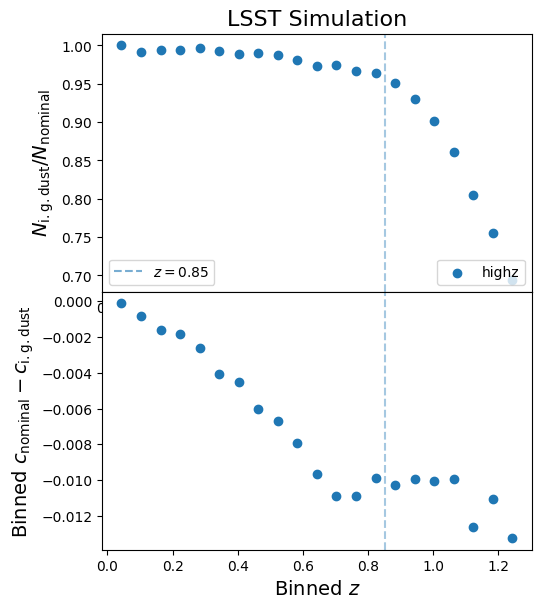

In [22]:
#DEEP
z_drop_deep = plot_drop(BBC_P21[create_filt(BBC_P21)&(BBC_P21['FIELD']=='DDF')],BBC_P21_corr_max[create_filt(BBC_P21_corr_max)&(BBC_P21_corr_max['FIELD']=='DDF')])
# plt.savefig("pdfs/LSST_sim_compare.pdf",bbox_inches='tight')
plt.show()

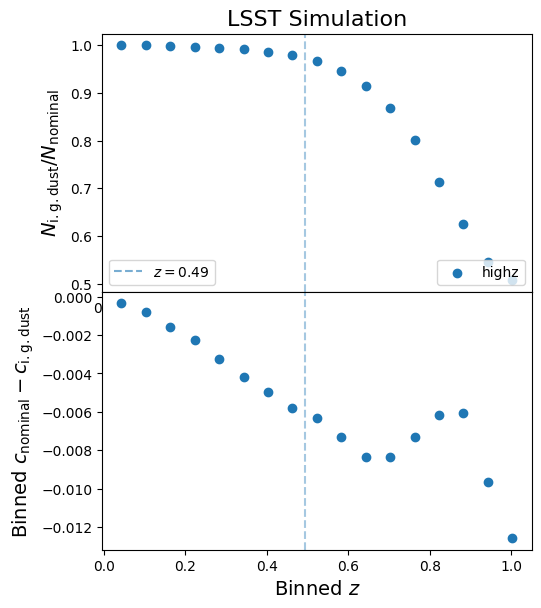

In [23]:
#SHALLOW
z_drop_shallow = plot_drop(BBC_P21[create_filt(BBC_P21)&(BBC_P21['FIELD']=='WFD')],BBC_P21_corr_max[create_filt(BBC_P21_corr_max)&(BBC_P21_corr_max['FIELD']=='WFD')])
plt.show()

In [24]:
""" MEANS splitting by field shallow/deep """
def calc_c_vs_z(data,sims_list,zmin=0.0,zmax=0.1,delta=0.1,N=15,offset=0):
    sim = sims_list[0]
    
    zmin = 0.1
    zmax = 0.2
    delta = 0.1 #was at 0.2 and zmax at 0.3

    z_means = []
    shallow_data_c_means = []
    shallow_data_c_stds = []

    shallow_sim_c_means = []
    shallow_sim_c_stds = []
    
    deep_data_c_means = []
    deep_data_c_stds = []

    deep_sim_c_means = []
    deep_sim_c_stds = []

    
    total_N_data = 0

    for i in range(N): #was at 5
        shallow_data_z_filt = (data['zHD'] <= z_drop_shallow) & (data['FIELD'] == 'WFD') & (data['zHD'] > zmin) & (data['zHD'] <= zmax) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)

        bins = np.arange(-0.3,0.35,0.05)

        #data  
        if (z_drop_shallow - zmin) > 0.04:
            shallow_data_c_means.append(np.mean(data['c'][shallow_data_z_filt]))
            shallow_data_c_stds.append(np.std(data['c'][shallow_data_z_filt])/np.sqrt(len(data['c'][shallow_data_z_filt])))

        deep_data_z_filt = (data['zHD'] <= z_drop_deep) & (data['FIELD'] == 'DDF') & (data['zHD'] > zmin) & (data['zHD'] <= zmax) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)

        if (z_drop_deep - zmin) > 0.04:
            deep_data_c_means.append(np.mean(data['c'][deep_data_z_filt]))
            deep_data_c_stds.append(np.std(data['c'][deep_data_z_filt])/np.sqrt(len(data['c'][deep_data_z_filt])))

        total_N_data+=len(data[shallow_data_z_filt])
        total_N_data+=len(data[deep_data_z_filt])

        
        #sims
        shallow_sim_z_filt = (sim['zHD'] <= z_drop_shallow) & (sim['FIELD'] == 'WFD') & (sim['zHD'] > zmin) & (sim['zHD'] <= zmax) & (np.abs(sim['c']) < 0.3) & (np.abs(sim['x1']) < 3) & (sim['x1ERR'] < 1) & (sim['PKMJDERR'] < 2) & (sim['FITPROB'] > 0.001) & (sim['SIM_AV'] > -9)

        if (z_drop_shallow - zmin) > 0.04:
            shallow_sim_c_means.append(np.mean(sim['c'][shallow_sim_z_filt])+offset)
            shallow_sim_c_stds.append(np.std(sim['c'][shallow_sim_z_filt])/np.sqrt(len(sim['c'][shallow_sim_z_filt])))

        deep_sim_z_filt = (sim['zHD'] <= z_drop_deep) & (sim['FIELD'] == 'DDF') & (sim['zHD'] > zmin) & (sim['zHD'] <= zmax) & (np.abs(sim['c']) < 0.3) & (np.abs(sim['x1']) < 3) & (sim['x1ERR'] < 1) & (sim['PKMJDERR'] < 2) & (sim['FITPROB'] > 0.001) & (sim['SIM_AV'] > -9)

        if (z_drop_deep - zmin) > 0.04:
            deep_sim_c_means.append(np.mean(sim['c'][deep_sim_z_filt])+offset)
            deep_sim_c_stds.append(np.std(sim['c'][deep_sim_z_filt])/np.sqrt(len(sim['c'][deep_sim_z_filt])))

        z_means.append((zmin+zmax)/2)                           


        zmin+=delta
        zmax+=delta
    print(total_N_data)
    
    
    z_means = np.array(z_means)
    shallow_data_c_means = np.array(shallow_data_c_means)
    shallow_data_c_stds = np.array(shallow_data_c_stds)
    shallow_sim_c_means = np.array(shallow_sim_c_means)
    shallow_sim_c_stds = np.array(shallow_sim_c_stds)
    
    deep_data_c_means = np.array(deep_data_c_means)
    deep_data_c_stds = np.array(deep_data_c_stds)
    deep_sim_c_means = np.array(deep_sim_c_means)
    deep_sim_c_stds = np.array(deep_sim_c_stds)
    
    return (z_means,shallow_data_c_means,shallow_data_c_stds,shallow_sim_c_means,shallow_sim_c_stds,deep_data_c_means,deep_data_c_stds,deep_sim_c_means,deep_sim_c_stds)

In [25]:
def plot_c_vs_z(z,c,cerr=[],label='',sim=True,color='C0'):
    """ plot one at a time (don't say plt.show()) """
    #sims
    if sim == True:
        plt.plot(z,c,label=label,color=color)
        if len(cerr)>0:
            plt.errorbar(z,c,yerr=cerr,ls='none',zorder=1,alpha=0.8,color=color,capsize=2,lw=2)
    #data
    else:
        plt.scatter(z,c,label=label,color=color)
        if len(cerr)>0:
            plt.errorbar(z,c,yerr=cerr,ls='none',zorder=1,alpha=0.4,color=color)
        
    
        
    plt.xlabel("$z$",fontsize=16)
    plt.ylabel("mean $c$",fontsize=16)
#     plt.xlim(0.0,1.1)
#     plt.ylim(-0.12,0.07)
    plt.legend(loc='upper right',fontsize=16)

In [26]:
def chi2(data,sim,data_err):
    return np.sum((np.array(data)-np.array(sim))**2/np.array(data_err)**2)

In [27]:
mz,sdc,sdc_s,ssc,ssc_s,ddc,ddc_s,dsc,dsc_s = calc_c_vs_z(P21,[BBC_P21],zmin=0.1,zmax=0.2)
_,_,_,ssc2,ssc_s2,_,_,dsc2,dsc_s2 = calc_c_vs_z(P21,[BBC_P21],zmin=0.1,zmax=0.2)
_,_,_,ssc3,ssc_s3,_,_,dsc3,dsc_s3 = calc_c_vs_z(P21,[BBC_P21_corr_max],zmin=0.1,zmax=0.2)

_,_,_,ssc4,ssc_s4,_,_,dsc4,dsc_s4 = calc_c_vs_z(P21,[BBC_P21_corr_med],zmin=0.1,zmax=0.2)
_,_,_,ssc5,ssc_s5,_,_,dsc5,dsc_s5 = calc_c_vs_z(P21,[BBC_P21_corr_min],zmin=0.1,zmax=0.2)

82952
82952
82952
82952
82952


In [28]:
#Fit for an offset between Data and Sim

def weighted_mean_difference(A, B, sigma_A, sigma_B):
    """
    Compute the weighted mean difference between two datasets A and B,
    taking into account their uncertainties sigma_A and sigma_B.

    Parameters:
    A (array-like): First set of values.
    B (array-like): Second set of values.
    sigma_A (array-like): Uncertainties associated with A.
    sigma_B (array-like): Uncertainties associated with B.

    Returns:
    tuple: (weighted mean difference, uncertainty of the weighted mean)
    """
    # Compute differences and propagated uncertainties
    D = np.array(A) - np.array(B)
    sigma_D = np.sqrt(np.array(sigma_A)**2 + np.array(sigma_B)**2)

    # Compute weighted mean difference
    weights = 1 / sigma_D**2
    D_mean = np.sum(D * weights) / np.sum(weights)

    # Compute uncertainty of the weighted mean
    sigma_D_mean = np.sqrt(1 / np.sum(weights))

    return D_mean, sigma_D_mean

In [29]:
wmd2 = weighted_mean_difference(dsc2,ddc,dsc_s2,ddc_s)[0]
wmd3 = weighted_mean_difference(dsc3,ddc,dsc_s3,ddc_s)[0]
print(wmd2)
print(wmd3)

wmd4 = weighted_mean_difference(dsc4,ddc,dsc_s4,ddc_s)[0]
wmd5 = weighted_mean_difference(dsc5,ddc,dsc_s5,ddc_s)[0]

swmd2 = weighted_mean_difference(ssc2,sdc,ssc_s2,sdc_s)[0]
swmd3 = weighted_mean_difference(ssc3,sdc,ssc_s3,sdc_s)[0]
swmd4 = weighted_mean_difference(ssc4,sdc,ssc_s4,sdc_s)[0]
swmd5 = weighted_mean_difference(ssc5,sdc,ssc_s5,sdc_s)[0]

0.002870552304030251
0.01088306658583012


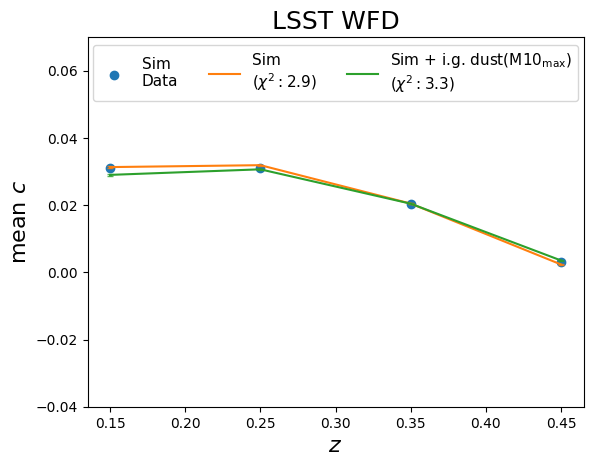

In [34]:
plt.title("LSST WFD",fontsize=18)
plot_c_vs_z(mz[0:len(sdc)],sdc,cerr=sdc_s,label='Sim\nData',sim=False)
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc2)-swmd2,cerr=ssc_s2,label=f'Sim \n($\chi^2:{chi2(sdc,ssc2-swmd2,sdc_s):.1f}$)',color='C1')
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc3)-swmd3,cerr=ssc_s3,label=f'Sim + i.g. dust(M10$_\mathrm{{max}}$)\n($\chi^2:{chi2(sdc,ssc3-swmd3,sdc_s):.1f}$)',color='C2')


legend1 = plt.legend(loc="upper center",ncol=3,fontsize=11)

# plot_c_vs_z(mz[0:len(sdc)],np.array(ssc4)-swmd4,cerr=ssc_s4,label=f'P21 + i.g. dust \n($\chi^2:{chi2(sdc,ssc4-swmd4,sdc_s):.1f}$)',color='C3')
# plot_c_vs_z(mz[0:len(sdc)],np.array(ssc5)-swmd5,cerr=ssc_s5,label=f'P21 + i.g. dust \n($\chi^2:{chi2(sdc,ssc5-swmd5,sdc_s):.1f}$)',color='C4')
# ax = plt.gca()

# blue_dotted = mlines.Line2D([], [], color="C3", linestyle="-", label=f'P21 + i.g. dust(M10$_\mathrm{{med}}$)\n($\chi^2:{chi2(sdc,ssc4-swmd4,sdc_s):.1f}$)',alpha=0.6)
# orange_dotted = mlines.Line2D([], [], color="C4", linestyle="-", label=f'P21 + i.g. dust(M10$_\mathrm{{min}}$) \n($\chi^2:{chi2(sdc,ssc5-swmd5,sdc_s):.1f}$)',alpha=0.6)
# legend2 = ax.legend(handles=[blue_dotted,orange_dotted],loc='lower center',ncol=2,fontsize=11)
# ax2.get_legend().remove()
plt.ylim(-0.04,0.07)
# plt.xlim(0,1)
# ax.add_artist(legend1)
# plt.savefig("pngs/LSST_z>0.1_shallow_compare_c_vs_z.png",bbox_inches='tight')
# plt.savefig("pdfs/LSST_z>0.1_shallow_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()

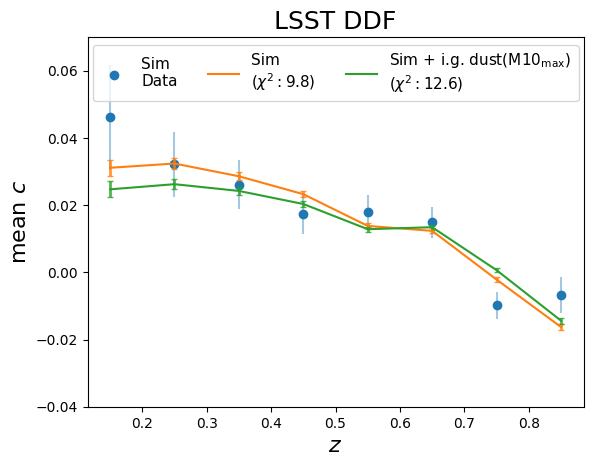

In [38]:
plt.title("LSST DDF",fontsize=18)
plot_c_vs_z(mz[0:len(ddc)],ddc,cerr=ddc_s,label='Sim\nData',sim=False)
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc2)-wmd2,cerr=dsc_s2,label=f'Sim \n($\chi^2:{chi2(ddc,dsc2-wmd2,ddc_s):.1f}$)',color='C1')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc3)-wmd3,cerr=dsc_s3,label=f'Sim + i.g. dust(M10$_\mathrm{{max}}$) \n($\chi^2:{chi2(ddc,dsc3-wmd3,ddc_s):.1f}$)',color='C2')


legend1 = plt.legend(loc="upper center",ncol=3,fontsize=11)

# plot_c_vs_z(mz[0:len(ddc)],np.array(dsc4)-wmd4,cerr=dsc_s4,label=None,#f'P21 + 3 x i.g. dust \n($\chi^2:{chi2(ddc,dsc4,ddc_s):.1f}$)',
#             color='C3')
# plot_c_vs_z(mz[0:len(ddc)],np.array(dsc5)-wmd5,cerr=dsc_s5,label=None,#f'P21 + 5 x i.g. dust \n($\chi^2:{chi2(ddc,dsc5,ddc_s):.1f}$)',
#             color='C4')
# ax = plt.gca()
# blue_dotted = mlines.Line2D([], [], color="C3", linestyle="-", label=f'P21 + i.g. dust(M10$_\mathrm{{med}}$)\n($\chi^2:{chi2(ddc,dsc4-wmd4,ddc_s):.1f}$)',alpha=0.6)
# orange_dotted = mlines.Line2D([], [], color="C4", linestyle="-", label=f'P21 + i.g. dust(M10$_\mathrm{{min}}$) \n($\chi^2:{chi2(ddc,dsc5-wmd5,ddc_s):.1f}$)',alpha=0.6)
# legend2 = ax.legend(handles=[blue_dotted,orange_dotted],loc='lower center',ncol=2,fontsize=11)
# legend2 = ax.legend(handles=[blue_dotted],loc='lower center',ncol=2,fontsize=11)

plt.ylim(-0.04,0.07)
# ax.add_artist(legend1)
# plt.savefig("pdfs/LSST_z>0.1_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()

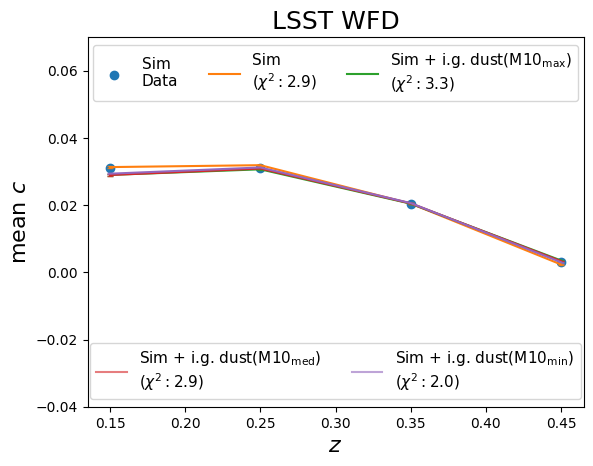

In [36]:
plt.title("LSST WFD",fontsize=18)
plot_c_vs_z(mz[0:len(sdc)],sdc,cerr=sdc_s,label='Sim\nData',sim=False)
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc2)-swmd2,cerr=ssc_s2,label=f'Sim \n($\chi^2:{chi2(sdc,ssc2-swmd2,sdc_s):.1f}$)',color='C1')
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc3)-swmd3,cerr=ssc_s3,label=f'Sim + i.g. dust(M10$_\mathrm{{max}}$)\n($\chi^2:{chi2(sdc,ssc3-swmd3,sdc_s):.1f}$)',color='C2')


legend1 = plt.legend(loc="upper center",ncol=3,fontsize=11)

plot_c_vs_z(mz[0:len(sdc)],np.array(ssc4)-swmd4,cerr=ssc_s4,label=f'Sim + i.g. dust \n($\chi^2:{chi2(sdc,ssc4-swmd4,sdc_s):.1f}$)',color='C3')
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc5)-swmd5,cerr=ssc_s5,label=f'Sim + i.g. dust \n($\chi^2:{chi2(sdc,ssc5-swmd5,sdc_s):.1f}$)',color='C4')
ax = plt.gca()

blue_dotted = mlines.Line2D([], [], color="C3", linestyle="-", label=f'Sim + i.g. dust(M10$_\mathrm{{med}}$)\n($\chi^2:{chi2(sdc,ssc4-swmd4,sdc_s):.1f}$)',alpha=0.6)
orange_dotted = mlines.Line2D([], [], color="C4", linestyle="-", label=f'Sim + i.g. dust(M10$_\mathrm{{min}}$) \n($\chi^2:{chi2(sdc,ssc5-swmd5,sdc_s):.1f}$)',alpha=0.6)
legend2 = ax.legend(handles=[blue_dotted,orange_dotted],loc='lower center',ncol=2,fontsize=11)
# ax2.get_legend().remove()
plt.ylim(-0.04,0.07)
# plt.xlim(0,1)
ax.add_artist(legend1)
# plt.savefig("pngs/LSST_z>0.1_vars_shallow_compare_c_vs_z.png",bbox_inches='tight')
# plt.savefig("pdfs/LSST_z>0.1_vars_shallow_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()

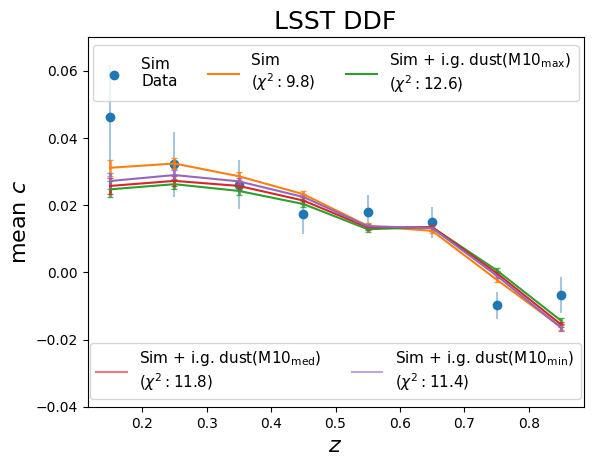

In [37]:
plt.title("LSST DDF",fontsize=18)
plot_c_vs_z(mz[0:len(ddc)],ddc,cerr=ddc_s,label='Sim\nData',sim=False)
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc2)-wmd2,cerr=dsc_s2,label=f'Sim \n($\chi^2:{chi2(ddc,dsc2-wmd2,ddc_s):.1f}$)',color='C1')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc3)-wmd3,cerr=dsc_s3,label=f'Sim + i.g. dust(M10$_\mathrm{{max}}$) \n($\chi^2:{chi2(ddc,dsc3-wmd3,ddc_s):.1f}$)',color='C2')


legend1 = plt.legend(loc="upper center",ncol=3,fontsize=11)

plot_c_vs_z(mz[0:len(ddc)],np.array(dsc4)-wmd4,cerr=dsc_s4,label=None,#f'P21 + 3 x i.g. dust \n($\chi^2:{chi2(ddc,dsc4,ddc_s):.1f}$)',
            color='C3')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc5)-wmd5,cerr=dsc_s5,label=None,#f'P21 + 5 x i.g. dust \n($\chi^2:{chi2(ddc,dsc5,ddc_s):.1f}$)',
            color='C4')
ax = plt.gca()
blue_dotted = mlines.Line2D([], [], color="C3", linestyle="-", label=f'Sim + i.g. dust(M10$_\mathrm{{med}}$)\n($\chi^2:{chi2(ddc,dsc4-wmd4,ddc_s):.1f}$)',alpha=0.6)
orange_dotted = mlines.Line2D([], [], color="C4", linestyle="-", label=f'Sim + i.g. dust(M10$_\mathrm{{min}}$) \n($\chi^2:{chi2(ddc,dsc5-wmd5,ddc_s):.1f}$)',alpha=0.6)
legend2 = ax.legend(handles=[blue_dotted,orange_dotted],loc='lower center',ncol=2,fontsize=11)
# legend2 = ax.legend(handles=[blue_dotted],loc='lower center',ncol=2,fontsize=11)

plt.ylim(-0.04,0.07)
ax.add_artist(legend1)
# plt.savefig("pdfs/LSST_z>0.1_vars_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()